In [6]:
from typing import TypedDict, Annotated
import operator
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

In [7]:
# State definition
class AgentState(TypedDict):
    user_id: int
    name: str
    age: int
    city: str

    analysis: Annotated[list[str], operator.add]
    recommendations: Annotated[list[str], operator.add]

    summary: str

In [8]:



# STAGE 1: Fetch user
def fetch_user(state: AgentState):
    print("Fetching user...")

    return {
        "name": "Ajay",
        "age": 27,
        "city": "Varanasi"
    }


# STAGE 2: Parallel analysis

def analyze_age(state: AgentState):
    print("Analyzing age...")

    return {
        "analysis": [
            f"User age is {state['age']}"
        ]
    }


def analyze_location(state: AgentState):
    print("Analyzing location...")

    return {
        "analysis": [
            f"User lives in {state['city']}"
        ]
    }


# STAGE 3: Parallel processing

def age_recommendation(state: AgentState):
    print("Generating age recommendation...")

    return {
        "recommendations": [
            "Recommend age-appropriate products"
        ]
    }


def location_recommendation(state: AgentState):
    print("Generating location recommendation...")

    return {
        "recommendations": [
            "Recommend local services"
        ]
    }


# STAGE 4: Final summary
def generate_summary(state: AgentState):
    print("Generating final summary...")

    return {
        "summary": (
            f"User: {state['name']}, "
            f"Age: {state['age']}, "
            f"City: {state['city']}. "
            f"Analysis: {state['analysis']}. "
            f"Recommendations: {state['recommendations']}"
        )
    }



In [9]:

# Build graph
builder = StateGraph(AgentState)

builder.add_node("fetch_user", fetch_user)

builder.add_node("analyze_age", analyze_age)
builder.add_node("analyze_location", analyze_location)

builder.add_node("age_recommendation", age_recommendation)
builder.add_node("location_recommendation", location_recommendation)

builder.add_node("generate_summary", generate_summary)


# Stage 1
builder.add_edge(START, "fetch_user")


# Stage 2: Parallel execution
builder.add_edge("fetch_user", "analyze_age")
builder.add_edge("fetch_user", "analyze_location")


# Stage 3: Both Stage 2 nodes must finish first
builder.add_edge("analyze_age", "age_recommendation")
builder.add_edge("analyze_location", "location_recommendation")


# Stage 4: Wait for both Stage 3 nodes
builder.add_edge(
    ["age_recommendation", "location_recommendation"],
    "generate_summary"
)

builder.add_edge("generate_summary", END)


# Compile
app = builder.compile()


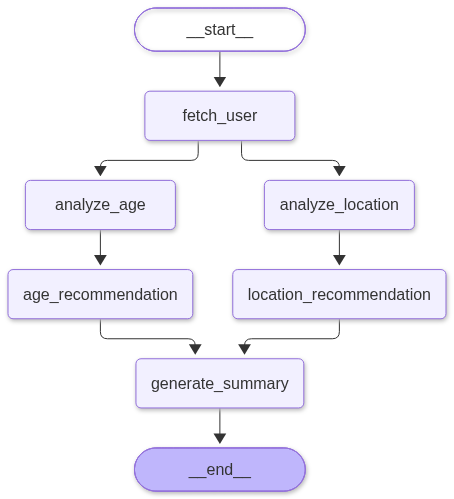

In [10]:
#Print Graph
display(
    Image(app.get_graph().draw_mermaid_png())
)

In [11]:


# Execute
result = app.invoke({
    "user_id": 101,
    "name": "",
    "age": 0,
    "city": "",
    "analysis": [],
    "recommendations": [],
    "summary": ""
})

print("\nFINAL RESULT:")
print(result)

Fetching user...
Analyzing age...
Analyzing location...
Generating age recommendation...
Generating location recommendation...
Generating final summary...

FINAL RESULT:
{'user_id': 101, 'name': 'Ajay', 'age': 27, 'city': 'Varanasi', 'analysis': ['User age is 27', 'User lives in Varanasi'], 'recommendations': ['Recommend age-appropriate products', 'Recommend local services'], 'summary': "User: Ajay, Age: 27, City: Varanasi. Analysis: ['User age is 27', 'User lives in Varanasi']. Recommendations: ['Recommend age-appropriate products', 'Recommend local services']"}
